# Прогноз банкротства компаний

Сравнение логистической регрессии, случайного леса и CatBoost на финансовых показателях
из [UCI Polish Companies Bankruptcy](https://archive.ics.uci.edu/dataset/365/polish+companies+bankruptcy+data).
Цель — оценить качество ранжирования наблюдений по риску метки банкротства на горизонте один год.

В `5year.arff` — 5 910 наблюдений, 64 показателя и метка `class`. По описанию UCI
этот файл соответствует прогнозу на один год; цифра в названии обозначает год наблюдения.
Другие файлы не объединяются с ним: у них другой горизонт, и независимость строк между файлами неизвестна.

Company ID и дат публикации отчётности нет. Поэтому проверка ниже не является оценкой на будущем периоде.

## 1. Библиотеки и настройки

Фиксируем seed и используем не более четырёх потоков при обучении деревьев.

In [ ]:
from pathlib import Path
import hashlib
import io
import urllib.request
import zipfile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.io import arff
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.calibration import calibration_curve
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score, brier_score_loss, confusion_matrix,
    log_loss, precision_recall_curve, roc_auc_score, roc_curve,
)
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from catboost import CatBoostClassifier

SEED = 42
FEATURES = [f"Attr{i}" for i in range(1, 65)]
pd.set_option("display.max_columns", 12)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## 2. Загрузка и проверка данных

Архив скачивается один раз и остаётся в локальной папке `data/`, исключённой из Git.
Если автоматическая загрузка недоступна, архив можно скачать по ссылке UCI и сохранить
как `data/raw/polish_companies_bankruptcy.zip`. Проверка SHA-256 фиксирует версию источника.

In [ ]:
SOURCE_URL = "https://archive.ics.uci.edu/static/public/365/polish%2Bcompanies%2Bbankruptcy%2Bdata.zip"
SOURCE_SHA256 = "17377929aa0b204bbf957e56462cf827c19fe4e2ce89f27dfbc77f9ea2bb16c9"
archive_path = Path("data/raw/polish_companies_bankruptcy.zip")
archive_path.parent.mkdir(parents=True, exist_ok=True)

if not archive_path.exists():
    urllib.request.urlretrieve(SOURCE_URL, archive_path)

assert hashlib.sha256(archive_path.read_bytes()).hexdigest() == SOURCE_SHA256

with zipfile.ZipFile(archive_path) as archive:
    text = archive.read("5year.arff").decode("utf-8")
    records, _ = arff.loadarff(io.StringIO(text))

frame = pd.DataFrame(records)
assert frame.columns.tolist() == FEATURES + ["class"]
frame["target"] = frame.pop("class").map({b"0": 0, b"1": 1})
assert frame.target.notna().all() and set(frame.target) == {0, 1}
frame[FEATURES] = frame[FEATURES].astype(float).replace([np.inf, -np.inf], np.nan)
frame["target"] = frame.target.astype(int)
frame["row_id"] = np.arange(1, len(frame) + 1)

print(f"Наблюдений: {len(frame)}, исходных признаков: {len(FEATURES)}")
display(frame[FEATURES[:5] + ["target"]].head())

Наблюдений: 5910, исходных признаков: 64


,Attr1,Attr2,Attr3,Attr4,Attr5,target
0,0.088238,0.55472,0.01134,1.0205,-66.5200,0
1,-0.006202,0.48465,0.23298,1.5998,6.1825,0
2,0.130240,0.22142,0.57751,3.6082,120.0400,0
3,-0.089951,0.88700,0.26927,1.5222,-55.9920,0
4,0.048179,0.55041,0.10765,1.2437,-22.9590,0


Несколько показателей, к которым будем обращаться при анализе. Полные определения —
в [описании UCI](https://archive.ics.uci.edu/dataset/365/polish+companies+bankruptcy+data).
Показатели уже рассчитаны авторами: исходных бухгалтерских форм здесь нет.

In [ ]:
feature_names = {
    "Attr1": "Чистая прибыль / активы",
    "Attr2": "Обязательства / активы",
    "Attr3": "Рабочий капитал / активы",
    "Attr4": "Оборотные активы / краткосрочные обязательства",
    "Attr10": "Собственный капитал / активы",
    "Attr21": "Продажи текущего года / продажи предыдущего",
    "Attr27": "Операционная прибыль / финансовые расходы",
    "Attr29": "Логарифм активов",
    "Attr34": "Операционные расходы / обязательства",
    "Attr51": "Краткосрочные обязательства / активы",
    "Attr56": "(Продажи - себестоимость) / продажи",
}
display(pd.Series(feature_names, name="Показатель").to_frame())

,Показатель
Attr1,Чистая прибыль / активы
Attr2,Обязательства / активы
Attr3,Рабочий капитал / активы
Attr4,Оборотные активы / краткосрочные обязательства
Attr10,Собственный капитал / активы
Attr21,Продажи текущего года / продажи предыдущего
Attr27,Операционная прибыль / финансовые расходы
Attr29,Логарифм активов
Attr34,Операционные расходы / обязательства
Attr51,Краткосрочные обязательства / активы


## 3. Разбиение с учётом точных дубликатов

Векторы с одинаковыми 64 показателями объединяем в группы. В одну группу могут входить
несколько строк; они целиком попадают в одну часть выборки. Hash не является идентификатором компании.
Точные повторы сохраняем: они могут быть разными наблюдениями с совпадающими значениями.

Пять стратифицированных групповых фолдов дают train (60%), validation (20%) и test (20%).

In [ ]:
frame["group"] = pd.util.hash_pandas_object(frame[FEATURES], index=False).map(lambda value: f"{value:016x}")
print("Повторных векторов признаков:", frame.group.duplicated().sum())
print("Групп с разными метками:", (frame.groupby("group").target.nunique() > 1).sum())

fold_number = np.full(len(frame), -1, dtype=int)
splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
for fold, (_, indices) in enumerate(splitter.split(frame[FEATURES], frame.target, frame.group)):
    fold_number[indices] = fold

assert (fold_number >= 0).all()
frame["split"] = np.where(fold_number < 3, "train", np.where(fold_number == 3, "validation", "test"))
assert frame.groupby("group")["split"].nunique().max() == 1

train = frame.loc[frame.split == "train"].copy()
validation = frame.loc[frame.split == "validation"].copy()
test = frame.loc[frame.split == "test"].copy()
assert all(part.target.nunique() == 2 for part in (train, validation, test))

X_train, y_train = train[FEATURES], train.target
X_val, y_val = validation[FEATURES], validation.target
X_test, y_test = test[FEATURES], test.target
display(frame.groupby("split").target.agg(rows="size", bankruptcies="sum", rate="mean"))

Повторных векторов признаков: 60
Групп с разными метками: 0


,rows,bankruptcies,rate
split,,,
test,1182,82,0.069374
train,3546,246,0.069374
validation,1182,82,0.069374


## 4. Исследование обучающей части

Изучаем пропуски, масштабы и распределения только на train. Отрицательные значения
не считаем ошибкой автоматически: убыток и отрицательный капитал экономически осмысленны.
Большие отношения могут возникать при маленьком знаменателе.

,missing_rate,median,p01,p99
Attr37,0.435702,3.88520,0.098252,1222.20000
Attr27,0.067964,0.96370,-138.888800,4782.75200
Attr45,0.043147,0.24307,-15.877080,56.16680
Attr60,0.043147,9.11080,1.369276,712.96360
Attr24,0.021715,0.16326,-1.236828,1.47740
Attr54,0.018895,1.41570,-4.824032,73.94672
Attr28,0.018895,0.51577,-5.536778,77.52548
Attr53,0.018895,1.26240,-6.912234,71.10642
Attr64,0.018895,4.19350,0.147980,355.21600
Attr21,0.016920,1.11410,0.367449,2.74567


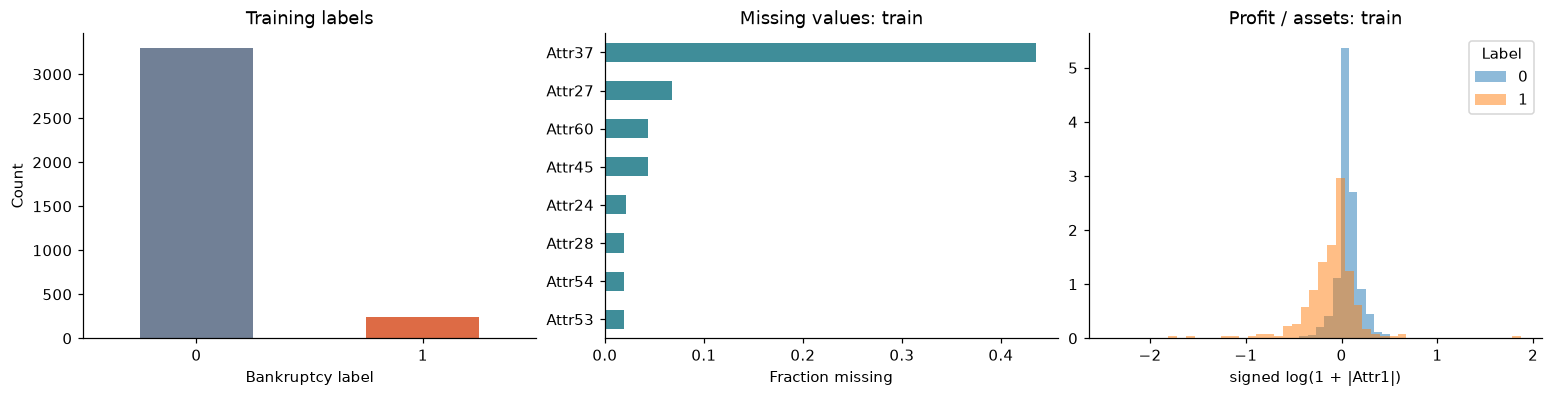

In [ ]:
summary = pd.DataFrame({
    "missing_rate": X_train.isna().mean(),
    "median": X_train.median(),
    "p01": X_train.quantile(.01),
    "p99": X_train.quantile(.99),
})
display(summary.sort_values("missing_rate", ascending=False).head(10))

fig, axes = plt.subplots(1, 3, figsize=(14, 3.5), layout="constrained")
y_train.value_counts().sort_index().plot.bar(ax=axes[0], color=["#718096", "#dd6b45"], rot=0)
axes[0].set(title="Training labels", xlabel="Bankruptcy label", ylabel="Count")
summary.missing_rate.nlargest(8).sort_values().plot.barh(ax=axes[1], color="#3f8d99")
axes[1].set(title="Missing values: train", xlabel="Fraction missing")
for label in (0, 1):
    values = X_train.loc[y_train == label, "Attr1"].dropna()
    axes[2].hist(np.sign(values) * np.log1p(abs(values)), bins=40, density=True, alpha=.5, label=str(label))
axes[2].set(title="Profit / assets: train", xlabel="signed log(1 + |Attr1|)")
axes[2].legend(title="Label")
plt.show()

Банкротств около 7%, так что accuracy здесь лучше не использовать.
Основная метрика — Average Precision (AP); дополнительно используем ROC-AUC.
AP постоянного score равен доле положительных меток. В sklearn AP не равен трапецеидальной PR-AUC.

## 5. Признаки и предобработка

Проверяем гипотезу: помогут ли число пропусков, флаги финансовых трудностей и два взаимодействия.
Они вычисляются из исходных показателей и не являются новыми источниками информации.
При неизвестном коэффициенте соответствующий флаг остаётся NaN.

In [ ]:
def add_features(X):
    result = X.copy()
    result["missing_ratio_count"] = X.isna().sum(axis=1).astype(float)
    result["negative_equity"] = (X.Attr10 < 0).astype(float).where(X.Attr10.notna())
    result["negative_working_capital"] = (X.Attr3 < 0).astype(float).where(X.Attr3.notna())
    result["liquidity_below_one"] = (X.Attr4 < 1).astype(float).where(X.Attr4.notna())
    result["negative_profit"] = (X.Attr1 < 0).astype(float).where(X.Attr1.notna())
    result["debt_exceeds_assets"] = (X.Attr2 > 1).astype(float).where(X.Attr2.notna())
    result["profit_x_liquidity"] = X.Attr1 * X.Attr4
    result["short_term_debt_share"] = X.Attr51 / X.Attr2.where(X.Attr2.abs() > 1e-8)
    return result.replace([np.inf, -np.inf], np.nan)


display(add_features(X_train).iloc[:3, -8:])

,missing_ratio_count,negative_equity,negative_working_capital,liquidity_below_one,negative_profit,debt_exceeds_assets,profit_x_liquidity,short_term_debt_share
0,0.0,0.0,0.0,0.0,0.0,0.0,0.090047,0.998828
1,1.0,0.0,0.0,0.0,1.0,0.0,-0.009922,0.801527
3,1.0,0.0,0.0,0.0,1.0,0.0,-0.136923,0.581330


Для линейной модели ограничиваем тяжёлые хвосты по квантилям train, заполняем NaN медианами,
добавляем индикаторы пропусков, применяем signed log и стандартизацию.
Signed log сжимает масштаб, сохраняя знак отрицательных значений.

Отдельно проверяем сокращение набора колонок: почти пустые, константные и сильно коррелирующие.
Параметры этих операций оцениваются внутри Pipeline на обучающем фолде, чтобы не использовать данные проверки.

In [ ]:
class QuantileClipper(TransformerMixin, BaseEstimator):
    def __init__(self, lower=.01, upper=.99):
        self.lower = lower
        self.upper = upper

    def fit(self, X, y=None):
        self.lower_ = X.quantile(self.lower)
        self.upper_ = X.quantile(self.upper)
        return self

    def transform(self, X):
        return X.clip(self.lower_, self.upper_, axis="columns")


class FeatureFilter(TransformerMixin, BaseEstimator):
    def __init__(self, max_missing=.95, max_correlation=.98):
        self.max_missing = max_missing
        self.max_correlation = max_correlation

    def fit(self, X, y=None):
        eligible = X.columns[(X.isna().mean() < self.max_missing) & (X.nunique() > 1)]
        correlations = X[eligible].corr().abs()
        self.selected_ = []
        for column in eligible:
            if not self.selected_ or not (correlations.loc[column, self.selected_] > self.max_correlation).any():
                self.selected_.append(column)
        return self

    def transform(self, X):
        return X[self.selected_].copy()


def signed_log1p(X):
    return np.sign(X) * np.log1p(np.abs(X))

## 6. Модели и одинаковые условия сравнения

Пространство поиска небольшое: два C у логистической регрессии, два размера листа у леса
и четыре варианта CatBoost. Для CatBoost сравниваем исходные признаки, добавленные,
сокращённый набор и меньшую глубину. Отдельно добавляем постоянный baseline.
Веса классов и oversampling в этом эксперименте не используются.

In [ ]:
models = {
    "dummy": Pipeline([
        ("impute", SimpleImputer(keep_empty_features=True)),
        ("model", DummyClassifier(strategy="prior")),
    ])
}

for C in (.1, 1.):
    models[f"logistic_C{C}"] = Pipeline([
        ("features", FunctionTransformer(add_features)),
        ("clip", QuantileClipper()),
        ("impute", SimpleImputer(strategy="median", add_indicator=True, keep_empty_features=True)),
        ("log", FunctionTransformer(signed_log1p)),
        ("scale", StandardScaler()),
        ("model", LogisticRegression(C=C, max_iter=3000, random_state=SEED)),
    ])

for leaf in (3, 10):
    models[f"forest_leaf{leaf}"] = Pipeline([
        ("features", FunctionTransformer(add_features)),
        ("impute", SimpleImputer(strategy="median", add_indicator=True, keep_empty_features=True)),
        ("model", RandomForestClassifier(n_estimators=300, min_samples_leaf=leaf,
                    max_features="sqrt", random_state=SEED, n_jobs=4)),
    ])

for name, engineered, compact, depth in [
    ("catboost_raw", False, False, 5),
    ("catboost_engineered", True, False, 5),
    ("catboost_compact", True, True, 5),
    ("catboost_depth4", True, False, 4),
]:
    steps = []
    if engineered:
        steps.append(("features", FunctionTransformer(add_features)))
    if compact:
        steps.append(("filter", FeatureFilter()))
    steps.append(("model", CatBoostClassifier(iterations=450, depth=depth,
        learning_rate=.04, l2_leaf_reg=5, loss_function="Logloss", random_seed=SEED,
        thread_count=4, verbose=False, allow_writing_files=False, nan_mode="Min")))
    models[name] = Pipeline(steps)

print("Конфигураций:", len(models))

Конфигураций: 9


Внутри train используем три групповых фолда. На каждом создаём новую копию Pipeline.
Модель выбирается по среднему AP, стандартное отклонение фолдов не является доверительным интервалом.
При выборе конфигураций test и validation не используются. Итерации CatBoost фиксированы, early stopping нет.

In [ ]:
cv = list(StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=SEED)
          .split(X_train, y_train, train.group))
cv_rows = []

for name, model in models.items():
    for fold, (fit_idx, score_idx) in enumerate(cv):
        assert set(train.group.iloc[fit_idx]).isdisjoint(train.group.iloc[score_idx])
        fitted = clone(model).fit(X_train.iloc[fit_idx], y_train.iloc[fit_idx])
        probability = fitted.predict_proba(X_train.iloc[score_idx])[:, 1]
        cv_rows.append({
            "candidate": name,
            "family": name.split("_")[0],
            "fold": fold,
            "ap": average_precision_score(y_train.iloc[score_idx], probability),
            "roc_auc": roc_auc_score(y_train.iloc[score_idx], probability),
        })
    mean_ap = np.mean([row["ap"] for row in cv_rows if row["candidate"] == name])
    print(f"{name}: CV AP={mean_ap:.4f}")

cv_results = pd.DataFrame(cv_rows).groupby(["candidate", "family"], as_index=False).agg(
    cv_ap_mean=("ap", "mean"), cv_ap_std=("ap", "std"), cv_roc_auc=("roc_auc", "mean"),
).sort_values(["cv_ap_mean", "candidate"], ascending=[False, True])
display(cv_results.round(4))

winner = cv_results.iloc[0].candidate
finalists = cv_results.drop_duplicates("family").candidate.tolist()
print("Выбранная конфигурация:", winner)

dummy: CV AP=0.0694


logistic_C0.1: CV AP=0.6826


logistic_C1.0: CV AP=0.6891


forest_leaf3: CV AP=0.6259


forest_leaf10: CV AP=0.5375


...

catboost_engineered: CV AP=0.7848


catboost_compact: CV AP=0.7542


catboost_depth4: CV AP=0.7821


,candidate,family,cv_ap_mean,cv_ap_std,cv_roc_auc
3,catboost_raw,catboost,0.7894,0.0282,0.9567
2,catboost_engineered,catboost,0.7848,0.0276,0.9541
1,catboost_depth4,catboost,0.7821,0.0276,0.9529
0,catboost_compact,catboost,0.7542,0.0250,0.9406
8,logistic_C1.0,logistic,0.6891,0.0094,0.9190
7,logistic_C0.1,logistic,0.6826,0.0127,0.9207
6,forest_leaf3,forest,0.6259,0.0140,0.9216
5,forest_leaf10,forest,0.5375,0.0130,0.9107
4,dummy,dummy,0.0694,0.0000,0.5000


Выбранная конфигурация: catboost_raw


По CV выбран CatBoost на исходных показателях. Дополнительные признаки немного уступили ему
в среднем, разница мала относительно разброса фолдов. Корреляционный фильтр снизил AP сильнее.
Это не доказывает универсальное преимущество исходных показателей: вывод относится к данному протоколу.

Для финального сравнения оставляем лучшую CV-конфигурацию каждого семейства.

## 7. Порог дополнительной проверки

Обучаем представителей семейств на всём train. Порог выбираем на validation
по условной функции затрат `10 * FN + FP`. Это учебное допущение, а не измеренные потери банка.
Все одинаковые scores обрабатываются вместе. При равных затратах выбираем более высокий порог.
После этого модели и пороги фиксированы.

In [ ]:
FN_COST = 10
FP_COST = 1


def decision_metrics(y, probability, threshold):
    predicted = probability >= threshold
    tn, fp, fn, tp = confusion_matrix(y, predicted, labels=[0, 1]).ravel()
    return {
        "threshold": float(threshold), "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
        "precision": tp / (tp + fp) if tp + fp else 0.,
        "recall": tp / (tp + fn),
        "alert_rate": predicted.mean(),
        "cost_per_row": (FN_COST * fn + FP_COST * fp) / len(y),
    }


def choose_threshold(y, probability):
    values = np.r_[np.unique(probability), np.nextafter(probability.max(), np.inf)]
    table = pd.DataFrame([decision_metrics(y, probability, value) for value in values])
    best = table.sort_values(["cost_per_row", "threshold"], ascending=[True, False]).iloc[0]
    return float(best.threshold)


fitted_models, thresholds, validation_rows = {}, {}, []
for name in finalists:
    model = clone(models[name]).fit(X_train, y_train)
    fitted_models[name] = model
    probability = model.predict_proba(X_val)[:, 1]
    thresholds[name] = choose_threshold(y_val, probability)
    validation_rows.append({"model": name, **decision_metrics(y_val, probability, thresholds[name])})

display(pd.DataFrame(validation_rows).round(4))

,model,threshold,tn,fp,fn,tp,precision,recall,alert_rate,cost_per_row
0,catboost_raw,0.0622,1008,92,7,75,0.4491,0.9146,0.1413,0.1371
1,logistic_C1.0,0.0613,976,124,13,69,0.3575,0.8415,0.1633,0.2149
2,forest_leaf3,0.1961,1028,72,16,66,0.4783,0.8049,0.1168,0.1963
3,dummy,0.0694,1100,0,82,0,0.0000,0.0000,0.0000,0.6937


## 8. Важность признаков на validation

Перемешиваем каждый исходный показатель три раза и измеряем падение AP.
Производные признаки пересчитываются внутри Pipeline. Оценка зависит от модели и корреляций,
она не является причинным влиянием показателя на банкротство.

,feature,mean_ap_drop,std,description
20,Attr21,0.279432,0.016231,Продажи текущего года / продажи предыдущего
26,Attr27,0.258077,0.020840,Операционная прибыль / финансовые расходы
33,Attr34,0.100215,0.003187,Операционные расходы / обязательства
55,Attr56,0.049171,0.002914,(Продажи - себестоимость) / продажи
57,Attr58,0.040187,0.004219,См. определение UCI
34,Attr35,0.031118,0.001807,См. определение UCI
23,Attr24,0.029601,0.001133,См. определение UCI
45,Attr46,0.015610,0.003717,См. определение UCI
38,Attr39,0.015519,0.003568,См. определение UCI
48,Attr49,0.005946,0.000780,См. определение UCI


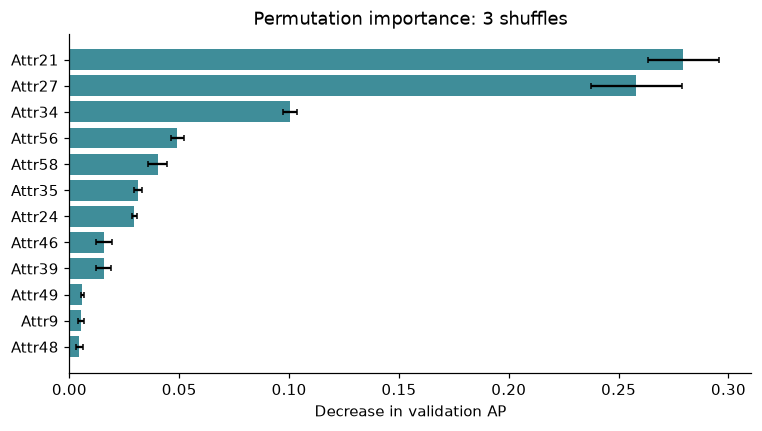

In [ ]:
best_model = fitted_models[winner]
baseline_ap = average_precision_score(y_val, best_model.predict_proba(X_val)[:, 1])
rng = np.random.default_rng(SEED)
importance_rows = []

for column in FEATURES:
    changes = []
    for _ in range(3):
        shuffled = X_val.copy()
        shuffled[column] = rng.permutation(shuffled[column].to_numpy())
        shuffled_ap = average_precision_score(y_val, best_model.predict_proba(shuffled)[:, 1])
        changes.append(baseline_ap - shuffled_ap)
    importance_rows.append({"feature": column, "mean_ap_drop": np.mean(changes), "std": np.std(changes)})

importance = pd.DataFrame(importance_rows).sort_values("mean_ap_drop", ascending=False)
importance["description"] = importance.feature.map(feature_names).fillna("См. определение UCI")
display(importance.head(10))

top = importance.head(12).sort_values("mean_ap_drop")
plt.figure(figsize=(8, 4))
plt.barh(top.feature, top.mean_ap_drop, xerr=top["std"], color="#3f8d99", capsize=2)
plt.xlabel("Decrease in validation AP")
plt.title("Permutation importance: 3 shuffles")
plt.show()

В данном запуске модель сильнее всего опирается на `Attr21` (изменение продаж),
`Attr27` (операционная прибыль / финансовые расходы) и `Attr34` (операционные расходы / обязательства).
Коррелирующие показатели могут подменять друг друга, поэтому малая важность отдельной колонки
не доказывает, что в ней нет информации.

## 9. Итоговая оценка на test

Помимо AP и ROC-AUC оцениваем вероятность через Brier и log loss, а также очередь проверки top 10%.
Precision top 10% — доля событий в очереди, recall — доля найденных событий из всех,
lift — отношение precision к базовой частоте. При одинаковых scores сохраняем порядок исходных строк.
Top 10% и численный порог — две разные политики.

In [ ]:
def ranking_metrics(y, probability):
    y = np.asarray(y)
    count = int(np.ceil(.1 * len(y)))
    top_indices = np.argsort(-probability, kind="stable")[:count]
    precision = y[top_indices].mean()
    return {
        "roc_auc": roc_auc_score(y, probability),
        "average_precision": average_precision_score(y, probability),
        "brier": brier_score_loss(y, probability),
        "log_loss": log_loss(y, probability, labels=[0, 1]),
        "precision_at_10pct": precision,
        "recall_at_10pct": y[top_indices].sum() / y.sum(),
        "lift_at_10pct": precision / y.mean(),
        "review_count": count,
    }


test_rows, test_probabilities = [], {}
for name in finalists:
    probability = fitted_models[name].predict_proba(X_test)[:, 1]
    assert np.isfinite(probability).all() and ((probability >= 0) & (probability <= 1)).all()
    test_probabilities[name] = probability
    test_rows.append({"model": name, **ranking_metrics(y_test, probability),
                     **decision_metrics(y_test, probability, thresholds[name])})

test_results = pd.DataFrame(test_rows).set_index("model")
display(test_results[["roc_auc", "average_precision", "brier", "log_loss",
                      "precision_at_10pct", "recall_at_10pct", "lift_at_10pct"]].round(4))
display(test_results.loc[[winner], ["threshold", "tp", "fp", "fn", "tn", "precision", "recall", "alert_rate"]].round(4))

winner_result = test_results.loc[winner]
found = round(winner_result.recall_at_10pct * y_test.sum())
print(f"Top 10%: {int(winner_result.review_count)} наблюдений, найдено {found} из {int(y_test.sum())} банкротств.")

,roc_auc,average_precision,brier,log_loss,precision_at_10pct,recall_at_10pct,lift_at_10pct
model,,,,,,,
catboost_raw,0.9555,0.8201,0.0258,0.1000,0.5546,0.8049,7.9947
logistic_C1.0,0.9080,0.6779,0.0358,0.1418,0.4874,0.7073,7.0256
forest_leaf3,0.9215,0.6361,0.0400,0.1469,0.4790,0.6951,6.9045
dummy,0.5000,0.0694,0.0646,0.2520,0.0000,0.0000,0.0000


,threshold,tp,fp,fn,tn,precision,recall,alert_rate
model,,,,,,,,
catboost_raw,0.0622,70,70,12,1030,0.5,0.8537,0.1184


Top 10%: 119 наблюдений, найдено 66 из 82 банкротств.


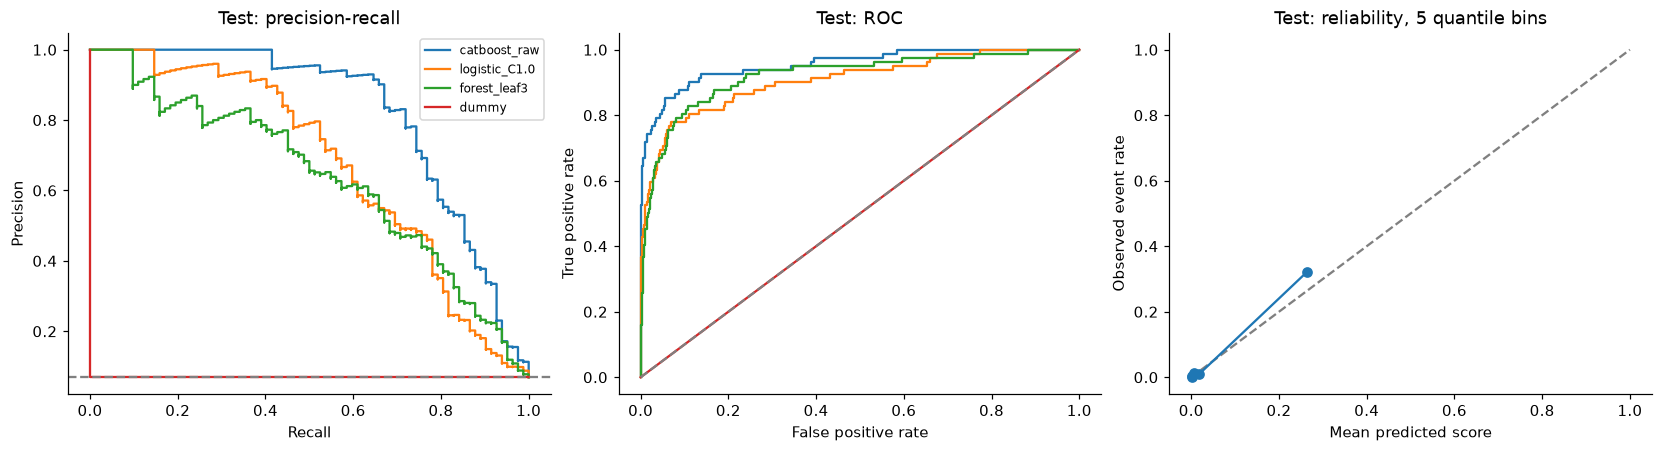

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), layout="constrained")
for name, probability in test_probabilities.items():
    precision, recall, _ = precision_recall_curve(y_test, probability)
    axes[0].step(recall, precision, where="post", label=name)
    fpr, tpr, _ = roc_curve(y_test, probability)
    axes[1].plot(fpr, tpr, label=name)

axes[0].axhline(y_test.mean(), linestyle="--", color="grey")
axes[0].set(title="Test: precision-recall", xlabel="Recall", ylabel="Precision")
axes[0].legend(fontsize=8)
axes[1].plot([0, 1], [0, 1], linestyle="--", color="grey")
axes[1].set(title="Test: ROC", xlabel="False positive rate", ylabel="True positive rate")
observed, predicted = calibration_curve(y_test, test_probabilities[winner], n_bins=5, strategy="quantile")
axes[2].plot([0, 1], [0, 1], linestyle="--", color="grey")
axes[2].plot(predicted, observed, marker="o")
axes[2].set(title="Test: reliability, 5 quantile bins", xlabel="Mean predicted score", ylabel="Observed event rate")
plt.show()

У CatBoost test ROC-AUC ≈ 0,955 и AP ≈ 0,820 при доле событий ≈ 0,069.
При бюджете 119 проверок найдены 66 из 82 банкротств: precision ≈ 55,5%, recall ≈ 80,5%, lift ≈ 8.
AP не означает долю правильно классифицированных компаний.

Численный порог с validation даёт другую нагрузку: 140 флагов, 70 TP, 70 FP и 12 FN.
На test мы не меняем порог и не перевыбираем модель. Лес имеет ROC-AUC выше логистической регрессии,
но AP ниже — пример различия этих метрик.

Reliability plot и Brier описывают вероятностный выход. Отдельной калибровки нет,
поэтому результат не рассматривается как проверенная банковская PD.

Оценим неопределённость фиксированных test-предсказаний с помощью 500 групповых bootstrap-перевыборок.
При выборе группы берём все её строки. Интервал не учитывает вариативность переобучения,
выбора модели и смену экономической среды.

In [ ]:
rng = np.random.default_rng(SEED)
groups = test.group.to_numpy()
unique_groups = np.unique(groups)
positions = {group: np.flatnonzero(groups == group) for group in unique_groups}
y_array = y_test.to_numpy()
probability = test_probabilities[winner]
bootstrap_scores = []

for _ in range(500):
    sampled_groups = rng.choice(unique_groups, len(unique_groups), replace=True)
    indices = np.concatenate([positions[group] for group in sampled_groups])
    if len(np.unique(y_array[indices])) < 2:
        continue
    bootstrap_scores.append([
        roc_auc_score(y_array[indices], probability[indices]),
        average_precision_score(y_array[indices], probability[indices]),
    ])

intervals = pd.DataFrame(np.quantile(bootstrap_scores, [.025, .975], axis=0).T,
                         index=["ROC-AUC", "AP"], columns=["2.5%", "97.5%"])
display(intervals.round(4))

,2.5%,97.5%
ROC-AUC,0.9299,0.9773
AP,0.7419,0.8836


## 10. Разбор ошибок

После фиксации результатов посмотрим FP и FN. Это описательный анализ:
по этим ошибкам не меняем модель в текущем эксперименте.

In [ ]:
errors = test[["row_id", "target", "Attr1", "Attr2", "Attr3", "Attr4", "Attr10"]].copy()
errors["score"] = test_probabilities[winner]
errors["prediction"] = (errors.score >= thresholds[winner]).astype(int)
false_positives = errors[(errors.target == 0) & (errors.prediction == 1)].sort_values("score", ascending=False)
false_negatives = errors[(errors.target == 1) & (errors.prediction == 0)].sort_values("score")
print("FP с самыми высокими scores:")
display(false_positives.head(3))
print("FN с самыми низкими scores:")
display(false_negatives.head(3))

FP с самыми высокими scores:


,row_id,target,Attr1,Attr2,Attr3,Attr4,Attr10,score,prediction
4242,4243,0,-0.054321,0.56823,-0.047489,0.87997,0.43177,0.767144,1
2619,2620,0,0.018179,0.00000,1.000000,NaN,1.00000,0.766735,1
2632,2633,0,0.054424,0.00172,0.998280,581.55000,0.99828,0.561524,1


FN с самыми низкими scores:


,row_id,target,Attr1,Attr2,Attr3,Attr4,Attr10,score,prediction
5768,5769,1,0.323590,0.141310,0.791840,6.6036,0.58733,0.003947,0
5890,5891,1,0.097567,0.178560,0.465540,3.6072,0.82141,0.004520,0
5630,5631,1,0.051022,0.052152,0.063516,2.5847,0.77623,0.008520,0


У FP №4243 отрицательны прибыль и рабочий капитал относительно активов, ликвидность ниже 1.
Это согласуется с гипотезой о финансовых трудностях, но банкротство в горизонте метки не наблюдалось.
У FN №5769 положительная прибыль, низкая долговая нагрузка и высокая текущая ликвидность,
однако событие произошло. Эти показатели не дают полного описания положения компании.
Без истории и контекста нельзя установить причины ошибок, модель использует все 64 показателя.

## Выводы и ограничения

-  CatBoost лучше ранжировал наблюдения по AP, чем линейный baseline и лес.
- Добавленные признаки и корреляционный отбор не улучшили CV AP. Близость raw и engineered не доказывает превосходство одного представления.
- Группировка исключает точные дубликаты между частями, но без company_id не исключает разные отчёты одной компании.
- Исторические польские данные не подтверждают переносимость на российские компании или банковский портфель.
- Банкротство в UCI отличается от дефолта по кредитному обязательству. Стоимости ошибок условные.
- Новые гипотезы после просмотра test требуют новой независимой финальной оценки.

## Источники

- Tomczak, S. (2016). [Polish Companies Bankruptcy, UCI](https://doi.org/10.24432/C5F600), лицензия CC BY 4.0.
- [Average Precision](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.average_precision_score.html),
  [перестановочная важность](https://scikit-learn.org/stable/modules/permutation_importance.html),
  [калибровка](https://scikit-learn.org/stable/modules/calibration.html).
- [Обработка пропусков CatBoost](https://catboost.ai/docs/en/concepts/algorithm-missing-values-processing).